# Invert for source depth / range

In [19]:
import os
import pickle
from itertools import combinations

import cmps
import matplotlib.pyplot as plt
import numpy as np
import pygenray as pr
import xarray as xr
from dotenv import find_dotenv, load_dotenv
from geopy.distance import geodesic

from nescafe23_fluctuations import tools
from nescafe23_fluctuations.source_localization import source_localization_iteration

_ = load_dotenv(find_dotenv())

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
Tx_idx = 0

## open arrival times

In [50]:
dss = tools.open_receptions()

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 23/23 [00:19<00:00,  1.16it/s]


In [3]:
with open(
    f"{os.environ['NESCAFE23_DATADIR']}dataproducts/peak_locations.pkl", "rb"
) as f:
    locations = pickle.load(f)

times = locations["times"]
angles = locations["angles"]
snrs = locations["snrs"]

In [7]:
ray_ids = list(times.keys())[7:]


difference_keys = list(combinations(ray_ids, 2))

In [12]:
Delta_Ts_obs = np.ones(len(difference_keys)) * np.nan

for k, diff_key in enumerate(difference_keys):
    Delta_Ts_obs[k] = times[diff_key[0]][Tx_idx] - times[diff_key[1]][Tx_idx]

## Iteration 0

In [13]:
fn = f"{os.environ['NESCAFE23_DATADIR']}environment_data/dataproducts/full_field_new.nc"
full_field = xr.open_dataset(fn)

In [14]:
front_location = 35e3

envi_field = full_field.assign_coords({
    "range": (full_field.range.values + front_location)
})
c = envi_field["c"]

bathy = xr.DataArray(
    np.linspace(4908, 4908, 100),
    dims=["range"],
    coords={"range": np.linspace(0, 200e3, 100)},
)

envi = pr.OceanEnvironment2D(sound_speed=c, bathymetry=bathy)

In [15]:
coords = {
    "SION": [39 + 37.194 / 60, -63 - 39.427 / 60],
    "SIOE": [38 + 45.906 / 60, -62 - 15.626 / 60],
}

source_depth0 = 2300
source_range0 = 0
launch_angles = np.linspace(-35, 35, 6000)
receiver_range0 = geodesic(coords["SIOE"], coords["SION"]).meters
num_range_save = 1000

receiver_depths0 = [1000]

c_source0 = float(
    envi.sound_speed.interp({"range": source_range0, "depth": source_depth0})
)
c_receiever0 = float(
    envi.sound_speed.interp({"range": receiver_range0, "depth": receiver_depths0[0]})
)

Ss0 = 1 / c_source0
Sr0 = 1 / c_receiever0

In [16]:
rays0 = pr.shoot_rays(
    source_depth0, source_range0, launch_angles, receiver_range0, num_range_save, envi
)
eigs0 = pr.find_eigenrays(
    rays0,
    receiver_depths0,
    source_depth0,
    source_range0,
    receiver_range0,
    num_range_save,
    envi,
)

Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 46/46 [00:07<00:00,  6.36it/s]


In [17]:
times_model0 = {}
angles_model0 = {}
pzs_model0 = {}
pzr_model0 = {}
pxr_model0 = {}
pxs_model0 = {}
px_model0 = {}

for ray_id in ray_ids:
    ray_id_pr, _ = tools.parse_ray_id(ray_id)

    ray_idx = np.where(eigs0.ray_id[0] == ray_id_pr)[0][-1]
    times_model0[ray_id] = eigs0.ts[0][ray_idx, -1]
    angles_model0[ray_id] = eigs0.received_angles[0][ray_idx]

    pzs_model0[ray_id] = eigs0.ps[0][ray_idx, 0]
    pzr_model0[ray_id] = eigs0.ps[0][ray_idx, -1]

    pxr_model0[ray_id] = np.sqrt(Sr0**2 - pzr_model0[ray_id] ** 2)
    pxs_model0[ray_id] = np.sqrt(Ss0**2 - pzs_model0[ray_id] ** 2)

    px_model0[ray_id] = 0.5 * (pxr_model0[ray_id] + pxs_model0[ray_id])

### compute residuals, and Jacobian

In [18]:
Delta_Ts_sim0 = np.ones(len(difference_keys)) * np.nan

for k, diff_key in enumerate(difference_keys):
    Delta_Ts_sim0[k] = times_model0[diff_key[0]] - times_model0[diff_key[1]]

DDelta_Ts0 = Delta_Ts_obs - Delta_Ts_sim0

In [19]:
E = np.zeros((len(DDelta_Ts0), 3))

for k in range(len(DDelta_Ts0)):
    E[k, 0] = pzs_model0[difference_keys[k][0]] - pzs_model0[difference_keys[k][1]]
    E[k, 1] = px_model0[difference_keys[k][0]] - px_model0[difference_keys[k][1]]
    E[k, 2] = pzr_model0[difference_keys[k][0]] - pzr_model0[difference_keys[k][1]]

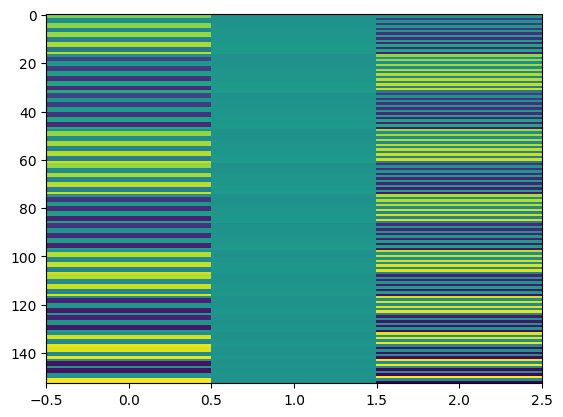

In [20]:
plt.imshow(E, aspect="auto", interpolation="none")

### compute update

In [21]:
S = np.diag([100, 4000, 0.5]) ** 2
# 100 [m] for source depth
# 1 [km] for range
# 3 [s] for common time offset

R = np.diag([(10e-3)] * len(DDelta_Ts0)) ** 2
# observation error of 10 [ms]

In [22]:
y = DDelta_Ts0.copy()
dx_hat = (
    np.linalg.inv(np.linalg.inv(S) + E.T @ np.linalg.inv(R) @ E)
    @ E.T
    @ np.linalg.inv(R)
    @ y
)
P = np.linalg.inv(np.linalg.inv(S) + E.T @ np.linalg.inv(R) @ E)

yerr = E @ P @ E.T

In [25]:
print(f"Source Depth: {source_depth0 + dx_hat[0]} ± {np.sqrt(P[0, 0])}")
print(f"Range: {receiver_range0 + dx_hat[1]} ± {np.sqrt(P[1, 1])}")
print(f"Time Offset: {dx_hat[2]} ± {np.sqrt(P[2, 2])}")

Source Depth: 2358.488456679485 ± 2.326198279842227
Range: 150356.97813582214 ± 36.01830541421924
Time Offset: -4.823233345290143 ± 0.4876652713045541


## Iteration 1

In [27]:
source_range1 = source_range0
source_depth1 = source_depth0 + dx_hat[0]
receiver_range1 = receiver_range0 + dx_hat[1]
receiver_depths1 = [receiver_depths0[0] + dx_hat[2]]

c_source1 = float(
    envi.sound_speed.interp({"range": source_range1, "depth": source_depth1})
)
c_receiever1 = float(
    envi.sound_speed.interp({"range": receiver_range1, "depth": receiver_depths1[0]})
)

Ss1 = 1 / c_source1
Sr1 = 1 / c_receiever1

In [28]:
rays1 = pr.shoot_rays(
    source_depth1, source_range1, launch_angles, receiver_range1, num_range_save, envi
)
eigs1 = pr.find_eigenrays(
    rays1,
    receiver_depths1,
    source_depth1,
    source_range1,
    receiver_range1,
    num_range_save,
    envi,
)

Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:05<00:00,  7.87it/s]


In [29]:
times_model1 = {}
angles_model1 = {}
pzs_model1 = {}
pzr_model1 = {}
pxr_model1 = {}
pxs_model1 = {}
px_model1 = {}

for ray_id in ray_ids:
    ray_id_pr, _ = tools.parse_ray_id(ray_id)

    ray_idx = np.where(eigs1.ray_id[0] == ray_id_pr)[0][-1]
    times_model1[ray_id] = eigs1.ts[0][ray_idx, -1]
    angles_model1[ray_id] = eigs1.received_angles[0][ray_idx]

    pzs_model1[ray_id] = eigs1.ps[0][ray_idx, 0]
    pzr_model1[ray_id] = eigs1.ps[0][ray_idx, -1]

    pxr_model1[ray_id] = np.sqrt(Sr1**2 - pzr_model1[ray_id] ** 2)
    pxs_model1[ray_id] = np.sqrt(Ss1**2 - pzs_model1[ray_id] ** 2)

    px_model1[ray_id] = 0.5 * (pxr_model1[ray_id] + pxs_model1[ray_id])

### compute residuals, and Jacobian

In [30]:
Delta_Ts_sim1 = np.ones(len(difference_keys)) * np.nan

for k, diff_key in enumerate(difference_keys):
    Delta_Ts_sim1[k] = times_model1[diff_key[0]] - times_model1[diff_key[1]]

DDelta_Ts1 = Delta_Ts_obs - Delta_Ts_sim1

In [32]:
E1 = np.zeros((len(DDelta_Ts1), 3))

for k in range(len(DDelta_Ts1)):
    E1[k, 0] = pzs_model1[difference_keys[k][0]] - pzs_model1[difference_keys[k][1]]
    E1[k, 1] = px_model1[difference_keys[k][0]] - px_model1[difference_keys[k][1]]
    E1[k, 2] = pzr_model1[difference_keys[k][0]] - pzr_model1[difference_keys[k][1]]

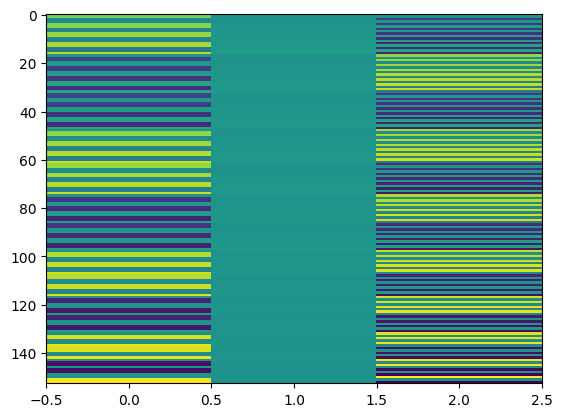

In [33]:
plt.imshow(E1, aspect="auto", interpolation="none")

### compute update

In [34]:
y1 = DDelta_Ts0.copy()
dx_hat1 = (
    np.linalg.inv(np.linalg.inv(S) + E1.T @ np.linalg.inv(R) @ E1)
    @ E1.T
    @ np.linalg.inv(R)
    @ y1
)
P1 = np.linalg.inv(np.linalg.inv(S) + E1.T @ np.linalg.inv(R) @ E1)

yerr1 = E1 @ P @ E1.T

In [35]:
print(f"Source Depth: {source_depth1 + dx_hat1[0]} ± {np.sqrt(P1[0, 0])}")
print(f"Range: {receiver_range1 + dx_hat1[1]} ± {np.sqrt(P1[1, 1])}")
print(f"Time Offset: {dx_hat1[2]} ± {np.sqrt(P1[2, 2])}")

Source Depth: 2415.871725659192 ± 2.29969746729541
Range: 147323.6289637774 ± 34.675670019276836
Time Offset: -4.877850209593181 ± 0.4873413484444477


## Iteration 2

In [36]:
source_range2 = source_range1
source_depth2 = source_depth1 + dx_hat1[0]
receiver_range2 = receiver_range1 + dx_hat1[1]
receiver_depths2 = [receiver_depths1[0] + dx_hat1[2]]

c_source2 = float(
    envi.sound_speed.interp({"range": source_range2, "depth": source_depth2})
)
c_receiever2 = float(
    envi.sound_speed.interp({"range": receiver_range2, "depth": receiver_depths2[0]})
)

Ss2 = 1 / c_source2
Sr2 = 1 / c_receiever2

In [37]:
rays2 = pr.shoot_rays(
    source_depth2, source_range2, launch_angles, receiver_range2, num_range_save, envi
)
eigs2 = pr.find_eigenrays(
    rays2,
    receiver_depths2,
    source_depth2,
    source_range2,
    receiver_range2,
    num_range_save,
    envi,
)

Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 39/39 [00:05<00:00,  7.31it/s]


In [38]:
times_model2 = {}
angles_model2 = {}
pzs_model2 = {}
pzr_model2 = {}
pxr_model2 = {}
pxs_model2 = {}
px_model2 = {}

for ray_id in ray_ids:
    ray_id_pr, _ = tools.parse_ray_id(ray_id)

    ray_idx = np.where(eigs2.ray_id[0] == ray_id_pr)[0][-1]
    times_model2[ray_id] = eigs2.ts[0][ray_idx, -1]
    angles_model2[ray_id] = eigs2.received_angles[0][ray_idx]

    pzs_model2[ray_id] = eigs2.ps[0][ray_idx, 0]
    pzr_model2[ray_id] = eigs2.ps[0][ray_idx, -1]

    pxr_model2[ray_id] = np.sqrt(Sr2**2 - pzr_model2[ray_id] ** 2)
    pxs_model2[ray_id] = np.sqrt(Ss2**2 - pzs_model2[ray_id] ** 2)

    px_model2[ray_id] = 0.5 * (pxr_model2[ray_id] + pxs_model2[ray_id])

### compute residuals, and Jacobian

In [39]:
Delta_Ts_sim2 = np.ones(len(difference_keys)) * np.nan

for k, diff_key in enumerate(difference_keys):
    Delta_Ts_sim2[k] = times_model2[diff_key[0]] - times_model2[diff_key[1]]

DDelta_Ts2 = Delta_Ts_obs - Delta_Ts_sim2

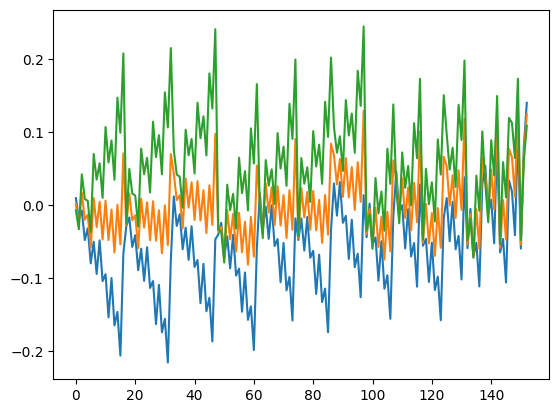

In [40]:
plt.plot(DDelta_Ts0)
plt.plot(DDelta_Ts1)
plt.plot(DDelta_Ts2)

In [32]:
E1 = np.zeros((len(DDelta_Ts1), 3))

for k in range(len(DDelta_Ts1)):
    E1[k, 0] = pzs_model1[difference_keys[k][0]] - pzs_model1[difference_keys[k][1]]
    E1[k, 1] = px_model1[difference_keys[k][0]] - px_model1[difference_keys[k][1]]
    E1[k, 2] = pzr_model1[difference_keys[k][0]] - pzr_model1[difference_keys[k][1]]

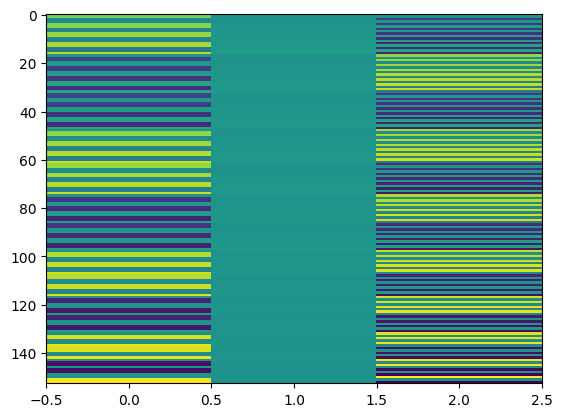

In [33]:
plt.imshow(E1, aspect="auto", interpolation="none")

### compute update

In [34]:
y1 = DDelta_Ts0.copy()
dx_hat1 = (
    np.linalg.inv(np.linalg.inv(S) + E1.T @ np.linalg.inv(R) @ E1)
    @ E1.T
    @ np.linalg.inv(R)
    @ y1
)
P1 = np.linalg.inv(np.linalg.inv(S) + E1.T @ np.linalg.inv(R) @ E1)

yerr1 = E1 @ P @ E1.T

In [35]:
print(f"Source Depth: {source_depth1 + dx_hat1[0]} ± {np.sqrt(P1[0, 0])}")
print(f"Range: {receiver_range1 + dx_hat1[1]} ± {np.sqrt(P1[1, 1])}")
print(f"Time Offset: {dx_hat1[2]} ± {np.sqrt(P1[2, 2])}")

Source Depth: 2415.871725659192 ± 2.29969746729541
Range: 147323.6289637774 ± 34.675670019276836
Time Offset: -4.877850209593181 ± 0.4873413484444477


# Build Source Localization Function

In [2]:
## Open Observed Arrival Times
Tx_idx = 0

with open(
    f"{os.environ['NESCAFE23_DATADIR']}dataproducts/peak_locations.pkl", "rb"
) as f:
    locations = pickle.load(f)

times = locations["times"]
angles = locations["angles"]
snrs = locations["snrs"]


ray_ids = list(times.keys())[7:]
difference_keys = list(combinations(ray_ids, 2))

Delta_Ts_obs = np.ones(len(difference_keys)) * np.nan

for k, diff_key in enumerate(difference_keys):
    Delta_Ts_obs[k] = times[diff_key[0]][Tx_idx] - times[diff_key[1]][Tx_idx]

In [3]:
## Create model environment object
fn = f"{os.environ['NESCAFE23_DATADIR']}environment_data/dataproducts/full_field_nlm.nc"
full_field = xr.open_dataset(fn)

front_location = 35e3

envi_field = full_field.assign_coords({
    "range": (full_field.range.values + front_location)
})
c = envi_field["c"]

bathy = xr.DataArray(
    np.linspace(4908, 4908, 100),
    dims=["range"],
    coords={"range": np.linspace(0, 200e3, 100)},
)

envi = pr.OceanEnvironment2D(sound_speed=c, bathymetry=bathy)

In [4]:
## Initial Guess and Priors

source_depth0 = 1500  # [m]
reciever_range0 = 153e3  # [m]
reciever_depth0 = 1000  # [m]

xs = [np.array([source_depth0, reciever_range0, reciever_depth0])]

S = np.diag([100, 4000, 0.5]) ** 2
# 100 [m] for source depth
# 1 [km] for range
# 3 [s] for common time offset

R = 2 * np.diag([(10e-3)] * len(difference_keys)) ** 2
# observation error of 10 [ms]

## iteration loop

In [7]:
source_depth0 = 1800  # [m]
reciever_range0 = 153e3  # [m]
reciever_depth0 = 1000  # [m]

x0 = np.array([source_depth0, reciever_range0, reciever_depth0])

Delta_Ts_sim = []
E = []
y = []
dx = []
P = []
rays = []
eigs = []
x = [x0]

for k in range(5):
    print(
        f"Iteration {k}: Source Depth = {x[k][0]}, Range = {x[k][1]}, Reciever Depth = {x[k][2]}"
    )
    Delta_Ts_simi, Ei, yi, dxi, Pi, raysi, eigsi = source_localization_iteration(
        x[k], S, R, envi, ray_ids, difference_keys, Delta_Ts_obs
    )

    Delta_Ts_sim.append(Delta_Ts_simi)
    E.append(Ei)
    y.append(yi)
    dx.append(dxi)
    P.append(Pi)
    rays.append(raysi)
    eigs.append(eigsi)

    # compute update for next iteration
    x.append(x[k] + dx[k])

Iteration 0: Source Depth = 1800.0, Range = 153000.0, Reciever Depth = 1000.0


Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 44/44 [00:08<00:00,  5.37it/s]


Iteration 1: Source Depth = 2353.4482533467335, Range = 150374.74989197304, Reciever Depth = 997.5087534842891


Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:04<00:00,  7.85it/s]


Iteration 2: Source Depth = 2361.250219064506, Range = 150405.42238364328, Reciever Depth = 994.9328758511649


Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:03<00:00, 10.29it/s]


Iteration 3: Source Depth = 2361.6359914553123, Range = 150410.1097391007, Reciever Depth = 992.288915851211


Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:03<00:00, 10.98it/s]


Iteration 4: Source Depth = 2361.798962314288, Range = 150414.96167808768, Reciever Depth = 989.5743491813191


Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:03<00:00, 10.36it/s]


<ErrorbarContainer object of 3 artists>

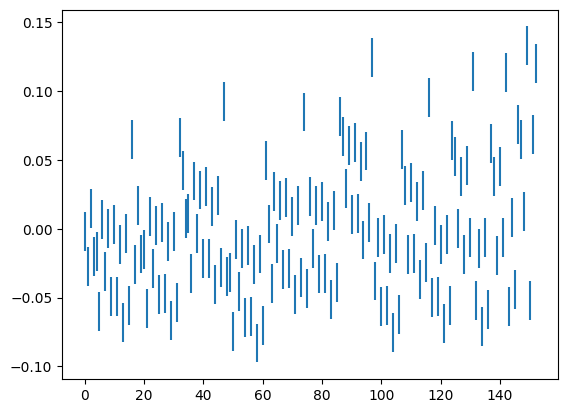

In [24]:
plt.errorbar(
    np.arange(len(difference_keys)), y[-1], np.sqrt(np.diag(R)), linestyle="none"
)

(-250.0, 250.0)

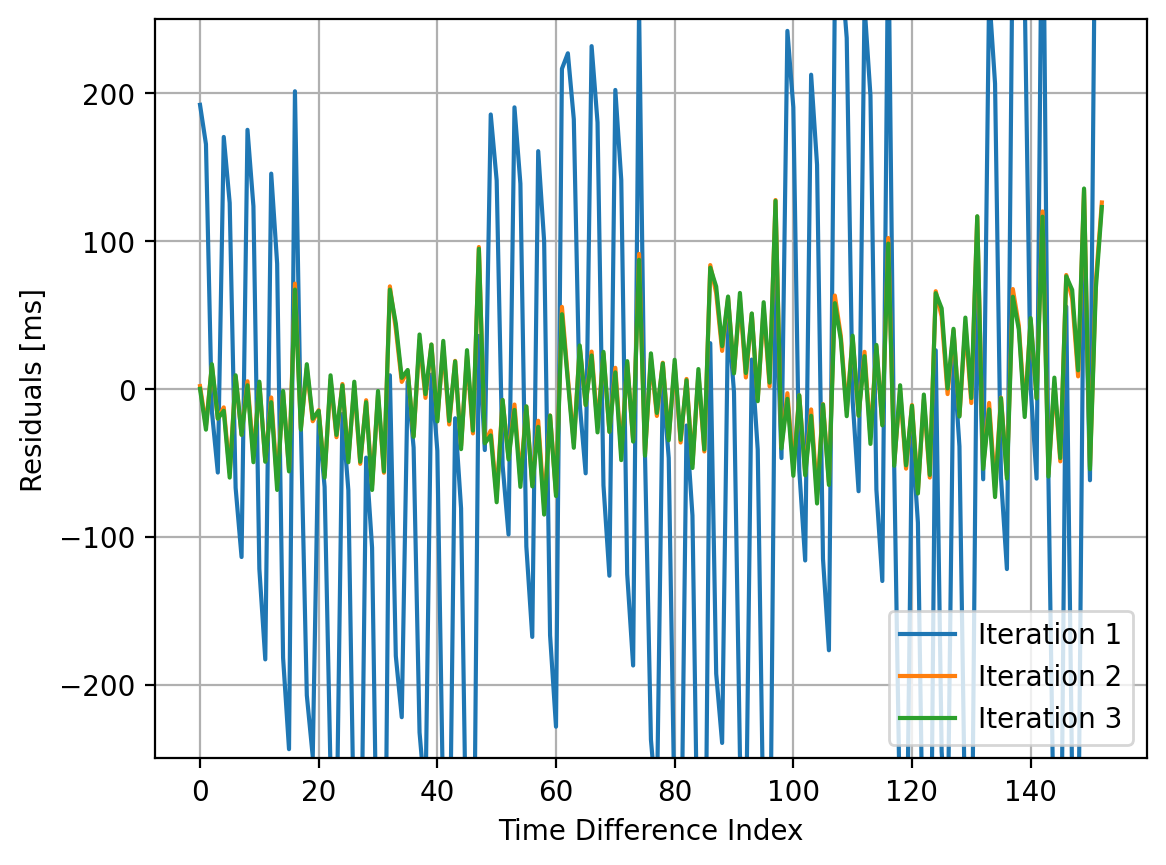

In [22]:
for k,y_single in enumerate(y[:3]):
    plt.plot(y_single*1000, label=f'Iteration {k+1}')

plt.legend()
plt.grid()
plt.ylabel('Residuals [ms]')
plt.xlabel('Time Difference Index')

plt.ylim([-250,250])

In [119]:
source_depth0 = 1800  # [m]
reciever_range0 = 153e3  # [m]
reciever_depth0 = 1000  # [m]

x0 = np.array([source_depth0, reciever_range0, reciever_depth0])
Delta_Ts_sim0, E0, y0, dx0, P0, rays0, eigs0 = tools.source_localization_iteration(
    x0, S, R, envi, ray_ids, difference_keys, Delta_Ts_obs
)

<unknown>:1158: SyntaxWarning: invalid escape sequence '\d'
<unknown>:1158: SyntaxWarning: invalid escape sequence '\d'
Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 44/44 [00:08<00:00,  5.27it/s]


In [120]:
x1 = xs0 + dx0
Delta_Ts_sim1, E1, y1, dx1, P1, rays1, eigs1 = tools.source_localization_iteration(
    x1, S, R, envi, ray_ids, difference_keys, Delta_Ts_obs
)

Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 33/33 [00:04<00:00,  7.95it/s]


In [121]:
x2 = x1 + dx1
Delta_Ts_sim2, E2, y2, dx2, P2, rays2, eigs2 = tools.source_localization_iteration(
    x2, S, R, envi, ray_ids, difference_keys, Delta_Ts_obs
)

Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:05<00:00,  6.64it/s]


In [122]:
x3 = x2 + dx2
Delta_Ts_sim1, E3, y3, dx3, P3, rays3, eigs3 = tools.source_localization_iteration(
    x3, S, R, envi, ray_ids, difference_keys, Delta_Ts_obs
)

Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:05<00:00,  7.56it/s]


In [127]:
x3

array([  2361.50872806, 150404.34909747,    999.37979522])

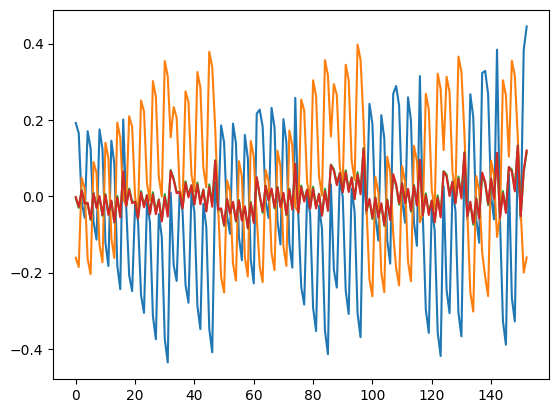

In [124]:
plt.plot(y0)
plt.plot(y1)
plt.plot(y2)
plt.plot(y3)

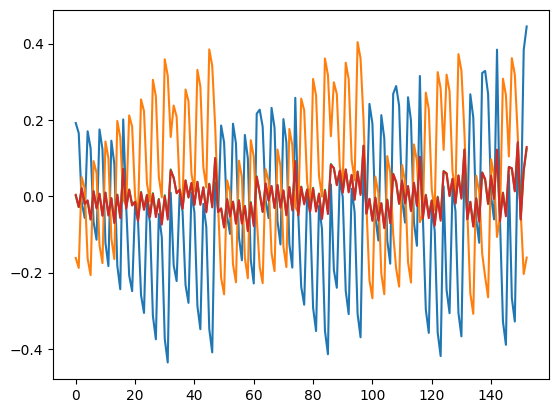

In [113]:
plt.plot(y0)
plt.plot(y1)
plt.plot(y2)
plt.plot(y3)

(100.0, 115.0)

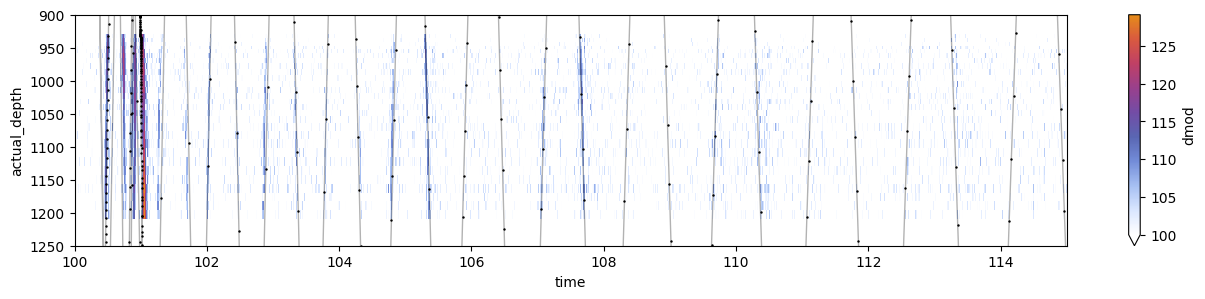

In [103]:
fig = plt.figure(figsize=(16, 3))
(20 * np.log10(np.abs(dss[Tx_idx][32:, :][:, ::10]))).swap_dims({
    "hydrophone": "actual_depth"
}).plot(vmin=100, cmap=cmps.plasma_coolwarm())

# plt.plot(rays0.ts[:,-1]-0.25, -rays0.zs[:,-1], lw=1, c='r')
plt.plot(rays3.ts[:, -1] - 0.25, -rays3.zs[:, -1], lw=1, c="k", alpha=0.3)
plt.scatter(rays3.ts[:, -1] - 0.25, -rays3.zs[:, -1], lw=0, s=3, c="k")


plt.ylim([1250, 900])
plt.xlim([100, 115])

(100.0, 102.0)

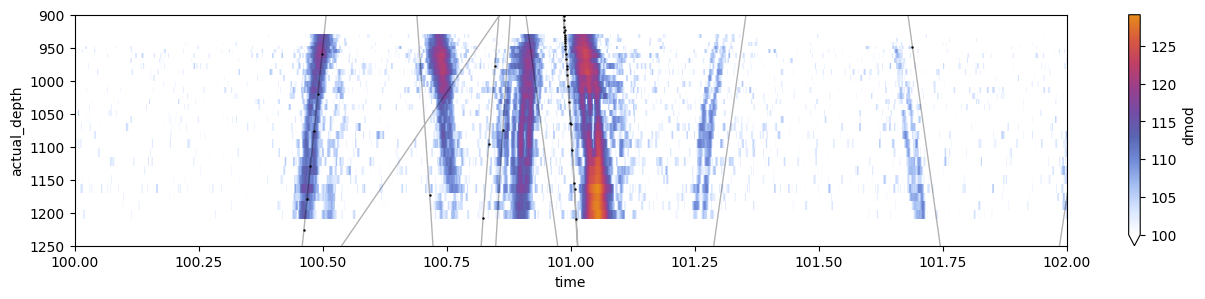

In [125]:
fig = plt.figure(figsize=(16, 3))
(20 * np.log10(np.abs(dss[Tx_idx][32:, :]))).swap_dims({
    "hydrophone": "actual_depth"
}).plot(vmin=100, cmap=cmps.plasma_coolwarm())

# plt.plot(rays0.ts[:,-1]-0.25, -rays0.zs[:,-1], lw=1, c='r')
plt.plot(rays3.ts[:, -1] - 0.25, -rays3.zs[:, -1], lw=1, c="k", alpha=0.3)
plt.scatter(rays3.ts[:, -1] - 0.25, -rays3.zs[:, -1], lw=0, s=3, c="k")


plt.ylim([1250, 900])
plt.xlim([100, 102])

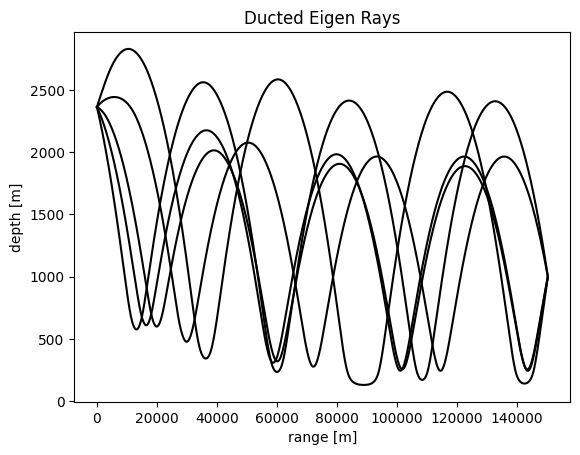

In [126]:
eigs3.plot_ducted()